<a href="https://colab.research.google.com/github/hasan2733/artificial-intelligence/blob/main/Notebooks/Implementation/CVD_paper_vs_corrected_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cardiovascular disease prediction: paper pipeline vs leakage-free pipeline

1. Run the paper's code WITH duplicates (Part 1).
2. Run the same code after removing duplicates (Part 2).
3. Run a corrected, tuned pipeline on the combined four-site data with per-model plots and final visualisations (Part 3).

Run the cells in order. Upload `heart.csv` (Kaggle) when asked. The final model is selected by cross-validated AUC on the training split, not by test score.

### Cell 1: install

Installs the extra packages Colab does not include. Run once; restart the runtime if Colab asks.

In [ ]:
!pip install -q tpot catboost lime shap imbalanced-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 1.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.1/215.1 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.6/117.6 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.2/86.2 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 14.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following depende

### Cell 2: imports + config

Loads all libraries and sets the random seed. `FAST = True` shrinks every search for a quick check; keep it `False` for real results.

In [ ]:
import os, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import loguniform, randint, uniform

from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_validate, RandomizedSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, VotingClassifier,
                              StackingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, roc_auc_score, roc_curve, auc, log_loss,
                             brier_score_loss, confusion_matrix, precision_recall_curve,
                             average_precision_score)
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from tpot import TPOTClassifier

SEED = 42
FAST = False     # True = quick smoke test (tiny searches). Keep False for real results.
np.random.seed(SEED)
sns.set_theme(style="whitegrid", font_scale=1.0)

### Cell 3: helper functions - metrics and per-model visualisation

Helper functions: honest metrics (AUC, log loss and Brier from probabilities), a four-panel figure for any model (confusion matrix, ROC, precision-recall, calibration) and bootstrap confidence intervals.

In [ ]:
def report(y_true, p, thr=0.5):
    """Honest metrics: AUC / log-loss / Brier use PROBABILITIES, others use the 0.5 threshold."""
    y_true = np.asarray(y_true); yy = (p >= thr).astype(int)
    return dict(n=len(y_true), Accuracy=accuracy_score(y_true, yy),
                BalAcc=balanced_accuracy_score(y_true, yy),
                Precision=precision_score(y_true, yy, zero_division=0),
                Recall=recall_score(y_true, yy), F1=f1_score(y_true, yy),
                MCC=matthews_corrcoef(y_true, yy),
                ROC_AUC=roc_auc_score(y_true, p) if len(np.unique(y_true)) > 1 else np.nan,
                PR_AUC=average_precision_score(y_true, p) if len(np.unique(y_true)) > 1 else np.nan,
                LogLoss=log_loss(y_true, np.clip(p, 1e-6, 1 - 1e-6), labels=[0, 1]),
                Brier=brier_score_loss(y_true, p))

def model_panel(name, y_true, p, thr=0.5, color="#4C72B0"):
    """4-panel figure: confusion matrix, ROC, precision-recall, calibration."""
    y_true = np.asarray(y_true); yy = (p >= thr).astype(int); r = report(y_true, p, thr)
    fig, ax = plt.subplots(1, 4, figsize=(20, 4.3))
    sns.heatmap(confusion_matrix(y_true, yy), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
                xticklabels=["No disease", "Disease"], yticklabels=["No disease", "Disease"])
    ax[0].set(xlabel="Predicted", ylabel="True", title=f"Confusion matrix\nAcc={r['Accuracy']:.3f}  MCC={r['MCC']:.3f}")
    fpr, tpr, _ = roc_curve(y_true, p)
    ax[1].plot(fpr, tpr, color=color, lw=2); ax[1].plot([0, 1], [0, 1], "--", c="gray")
    ax[1].fill_between(fpr, tpr, alpha=.12, color=color)
    ax[1].set(xlabel="False positive rate", ylabel="True positive rate", title=f"ROC (from probabilities)\nAUC={r['ROC_AUC']:.3f}")
    pr, rc, _ = precision_recall_curve(y_true, p)
    ax[2].plot(rc, pr, color=color, lw=2); ax[2].axhline(y_true.mean(), ls="--", c="gray")
    ax[2].set(xlabel="Recall", ylabel="Precision", ylim=(0, 1.02), title=f"Precision-Recall\nPR-AUC={r['PR_AUC']:.3f}")
    fy, fx = calibration_curve(y_true, p, n_bins=6, strategy="quantile")
    ax[3].plot([0, 1], [0, 1], "--", c="gray"); ax[3].plot(fx, fy, "o-", color=color, lw=2)
    ax[3].set(xlabel="Mean predicted probability", ylabel="Observed fraction positive",
              title=f"Calibration\nBrier={r['Brier']:.3f}")
    fig.suptitle(name, fontsize=14, fontweight="bold", y=1.04); plt.tight_layout(); plt.show()
    return r

def bootstrap_ci(y_true, p, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed); y_true = np.asarray(y_true); out = {"Accuracy": [], "ROC_AUC": [], "MCC": []}
    for _ in range(n_boot):
        i = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[i])) < 2: continue
        r = report(y_true[i], p[i])
        for k in out: out[k].append(r[k])
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in out.items()}

### Cell 4: load the Kaggle heart.csv (the paper's dataset)

Upload the original Kaggle `heart.csv` (the paper's dataset). The printout shows how many rows are duplicates.

In [ ]:
try:
    from google.colab import files
    if not os.path.exists("heart.csv"):
        uploaded = files.upload()          # choose heart.csv
except ImportError:
    pass
raw = pd.read_csv("heart.csv")
print("Shape:", raw.shape)
print("Duplicate rows:", raw.duplicated().sum(), "| unique rows:", len(raw.drop_duplicates()))
print("Class balance:\n", raw["target"].value_counts(normalize=True).round(3))
raw.head()

Saving heart.csv to heart.csv
Shape: (1025, 14)
Duplicate rows: 723 | unique rows: 302
Class balance:
 target
1    0.513
0    0.487
Name: proportion, dtype: float64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


### Cell 5: PART 1 - the paper's pipeline, as a function (original steps, original settings)

The paper's pipeline as a reusable function, copied step by step from the paper's notebook with the same settings. Paper-style metrics use hard labels for AUC and log loss; the function also draws honest probability-based plots.

In [ ]:
def paper_pipeline(df, title):
    X = df.drop(columns=["target"]); y = df["target"]
    # Split dataset into train and test (paper: 70/30, no stratify)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
    # Feature scaling
    scaler = StandardScaler(); X_train_scaled = scaler.fit_transform(X_train); X_test_scaled = scaler.transform(X_test)
    # Jittering (noise 0.02)
    X_train_noisy = X_train_scaled + np.random.normal(0, 0.02, X_train_scaled.shape)
    # SMOTE
    smote = SMOTE(sampling_strategy="auto", random_state=42)
    X_train_balanced, y_train_balanced = smote.fit_resample(X_train_noisy, y_train)
    # Polynomial expansion (interaction only)
    poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
    X_train_poly = poly.fit_transform(X_train_balanced); X_test_poly = poly.transform(X_test_scaled)
    # TPOT
    tpot = TPOTClassifier(generations=2 if FAST else 3, population_size=6 if FAST else 10, random_state=42, n_jobs=2)
    tpot.fit(X_train_poly, y_train_balanced); best_tpot_model = tpot.fitted_pipeline_
    # Base learners (paper's hyper-parameters)
    xgb_model = XGBClassifier(eval_metric="logloss", max_depth=2, learning_rate=0.01, n_estimators=30,
                              reg_alpha=5.0, reg_lambda=6.0, subsample=0.7, colsample_bytree=0.7, random_state=42)
    lgbm_model = LGBMClassifier(max_depth=2, learning_rate=0.01, n_estimators=30, reg_alpha=5.0, reg_lambda=6.0,
                                subsample=0.7, colsample_bytree=0.7, random_state=42, verbose=-1)
    fusion_model = VotingClassifier([("xgb", xgb_model), ("lgbm", lgbm_model), ("tpot", best_tpot_model)],
                                    voting="soft", weights=[0.3, 0.3, 0.4])
    fusion_model.fit(X_train_poly, y_train_balanced)
    fusion_cal = CalibratedClassifierCV(fusion_model, method="sigmoid", cv=5)
    fusion_cal.fit(X_train_poly, y_train_balanced)
    # Meta-learner (MLP + RF) trained on IN-SAMPLE probabilities (as in the paper)
    meta = VotingClassifier([("mlp", MLPClassifier(hidden_layer_sizes=(20,), activation="relu", solver="adam", alpha=5.0,
                                                   learning_rate="adaptive", max_iter=1500, early_stopping=True,
                                                   validation_fraction=0.1, random_state=42)),
                             ("rf", RandomForestClassifier(n_estimators=80, max_depth=3, random_state=42))], voting="soft")
    train_fp = fusion_cal.predict_proba(X_train_poly); test_fp = fusion_cal.predict_proba(X_test_poly)
    meta.fit(train_fp, y_train_balanced)
    tr_pred = meta.predict(train_fp); te_pred = meta.predict(test_fp); te_prob = meta.predict_proba(test_fp)[:, 1]
    # Paper-style metrics (note: AUC and log-loss computed from HARD labels, as in the paper)
    fpr, tpr, _ = roc_curve(y_test, te_pred)
    paper_metrics = dict(Train_Accuracy_on_SMOTE_data=accuracy_score(y_train_balanced, tr_pred),
                         Test_Accuracy=accuracy_score(y_test, te_pred), Precision=precision_score(y_test, te_pred),
                         Recall=recall_score(y_test, te_pred), F1=f1_score(y_test, te_pred),
                         MCC=matthews_corrcoef(y_test, te_pred), AUC_paper_way_hard_labels=auc(fpr, tpr),
                         LogLoss_paper_way_hard_labels=log_loss(y_test, te_pred))
    cv = cross_val_score(fusion_cal, X_train_poly, y_train_balanced,
                         cv=StratifiedKFold(10, shuffle=True, random_state=42), scoring="accuracy", n_jobs=-1)
    paper_metrics["10fold_CV_acc_on_SMOTE_data"] = cv.mean()
    print(f"\n===== {title} =====")
    print(f"rows: {len(df)} | train (after SMOTE): {len(y_train_balanced)} | test: {len(y_test)}")
    print("TPOT best pipeline:", [s[0] for s in best_tpot_model.steps])
    print(pd.Series(paper_metrics).round(4).to_string())
    # TPOT alone vs the 'fusion' (the paper claims fusion helps)
    tp_pred = tpot.predict(X_test_poly)
    print(f"TPOT alone test acc = {accuracy_score(y_test, tp_pred):.4f} | 'Fusion' test acc = {accuracy_score(y_test, te_pred):.4f}")
    r = model_panel(title, y_test, te_prob, color="#C44E52")
    return dict(metrics=paper_metrics, honest=r, y_test=np.asarray(y_test), p_test=te_prob, title=title)

### Cell 6: PART 1 - run the paper's code WITH duplicates (original Kaggle file, 1025 rows)

**Part 1:** run the paper's code WITH the duplicate rows (1,025 rows). Expect accuracy in the high 90s.

INFO:distributed.http.proxy:To route to workers diagnostics web server please install jupyter-server-proxy: python -m pip install jupyter-server-proxy
INFO:distributed.scheduler:State start
INFO:distributed.scheduler:  Scheduler at:     tcp://127.0.0.1:46435
INFO:distributed.scheduler:  dashboard at:  http://127.0.0.1:8787/status
INFO:distributed.scheduler:Registering Worker plugin shuffle
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:42703'
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:38133'
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:46199 name: 0
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:46199
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:39772
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:43987 name: 1
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:43987
INFO:distributed.core:Starting established connection to tcp://127


===== Paper pipeline - WITH duplicates (1025 rows) =====
rows: 1025 | train (after SMOTE): 754 | test: 308
TPOT best pipeline: ['robustscaler', 'passthrough', 'featureunion-1', 'featureunion-2', 'mlpclassifier']
Train_Accuracy_on_SMOTE_data     0.9973
Test_Accuracy                    0.9708
Precision                        0.9930
Recall                           0.9463
F1                               0.9691
MCC                              0.9424
AUC_paper_way_hard_labels        0.9700
LogLoss_paper_way_hard_labels    1.0532
10fold_CV_acc_on_SMOTE_data      0.9867
TPOT alone test acc = 0.9643 | 'Fusion' test acc = 0.9708


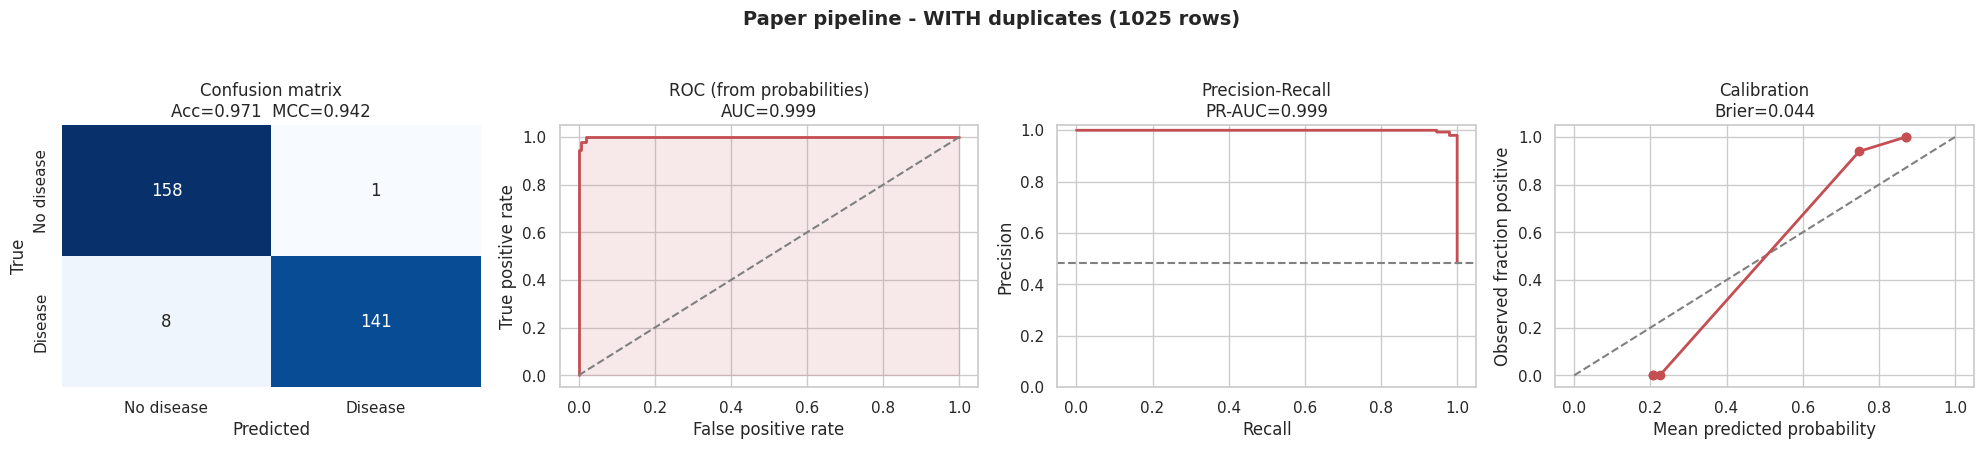

In [ ]:
res_paper_dup = paper_pipeline(raw, "Paper pipeline - WITH duplicates (1025 rows)")

### Cell 7: PART 2 - the SAME paper code after removing the duplicate rows (302 rows)

**Part 2:** run the identical code after removing the duplicates (302 unique patients). The drop in accuracy is the effect of duplicate leakage.

Removed 723 duplicate rows -> (302, 14)


INFO:distributed.scheduler:State start
INFO:distributed.scheduler:  Scheduler at:     tcp://127.0.0.1:38269
INFO:distributed.scheduler:  dashboard at:  http://127.0.0.1:8787/status
INFO:distributed.scheduler:Registering Worker plugin shuffle
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:41129'
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:36587'
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:36609 name: 1
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:36609
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:33936
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:38947 name: 0
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:38947
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:33948
INFO:distributed.scheduler:Receive client connection: Client-ed391fcc-c64c-11f1-81dc-0242ac1c000c
INFO:distributed.core:Starting establish


===== Paper pipeline - duplicates REMOVED (302 rows) =====
rows: 302 | train (after SMOTE): 242 | test: 91
TPOT best pipeline: ['robustscaler', 'selectfrommodel', 'featureunion-1', 'featureunion-2', 'xgbclassifier']
Train_Accuracy_on_SMOTE_data     0.8678
Test_Accuracy                    0.8242
Precision                        0.7547
Recall                           0.9302
F1                               0.8333
MCC                              0.6675
AUC_paper_way_hard_labels        0.8297
LogLoss_paper_way_hard_labels    6.3373
10fold_CV_acc_on_SMOTE_data      0.8183
TPOT alone test acc = 0.8242 | 'Fusion' test acc = 0.8242


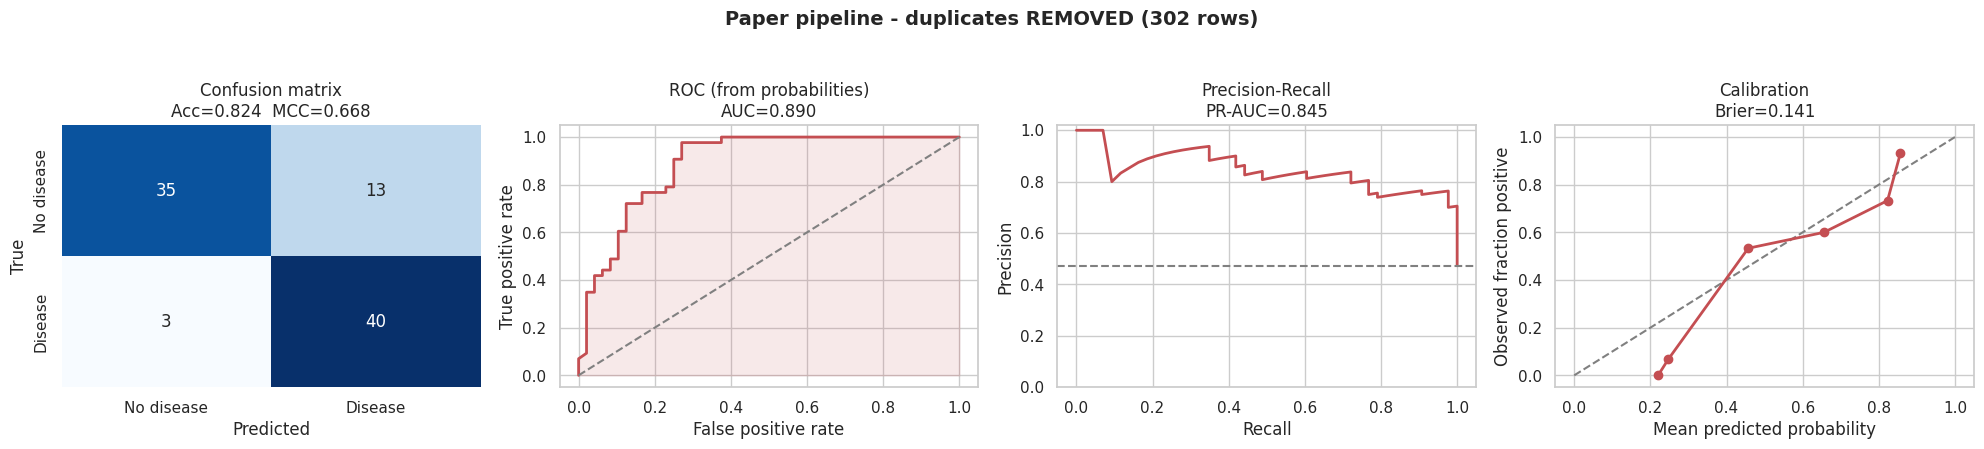

In [ ]:
raw_dedup = raw.drop_duplicates().reset_index(drop=True)
print("Removed", len(raw) - len(raw_dedup), "duplicate rows ->", raw_dedup.shape)
res_paper_nodup = paper_pipeline(raw_dedup, "Paper pipeline - duplicates REMOVED (302 rows)")

### Cell 8: PART 2 - side-by-side comparison

Side-by-side table and bar chart of the two paper-code runs.

                               with duplicates  duplicates removed
Train_Accuracy_on_SMOTE_data            0.9973              0.8678
Test_Accuracy                           0.9708              0.8242
Precision                               0.9930              0.7547
Recall                                  0.9463              0.9302
F1                                      0.9691              0.8333
MCC                                     0.9424              0.6675
AUC_paper_way_hard_labels               0.9700              0.8297
LogLoss_paper_way_hard_labels           1.0532              6.3373
10fold_CV_acc_on_SMOTE_data             0.9867              0.8183


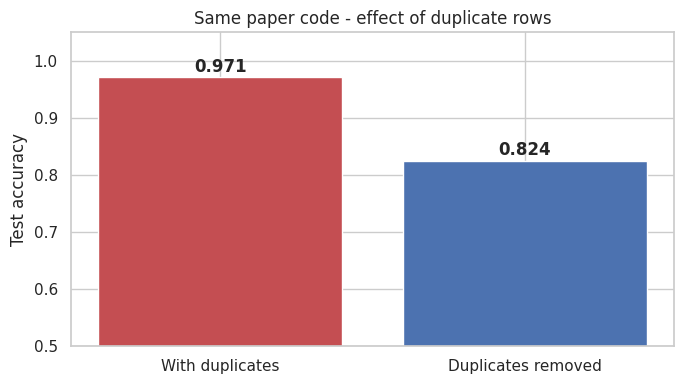

In [ ]:
cmp = pd.DataFrame({"with duplicates": res_paper_dup["metrics"], "duplicates removed": res_paper_nodup["metrics"]})
print(cmp.round(4).to_string())
fig, ax = plt.subplots(figsize=(7, 4))
vals = [res_paper_dup["metrics"]["Test_Accuracy"], res_paper_nodup["metrics"]["Test_Accuracy"]]
b = ax.bar(["With duplicates", "Duplicates removed"], vals, color=["#C44E52", "#4C72B0"])
for r_, v in zip(b, vals): ax.text(r_.get_x() + r_.get_width() / 2, v + .01, f"{v:.3f}", ha="center", fontweight="bold")
ax.set(ylim=(0.5, 1.05), ylabel="Test accuracy", title="Same paper code - effect of duplicate rows"); plt.tight_layout(); plt.show()

### Cell 9: PART 3 - build the combined four-site dataset (UCI) -> all_df

**Part 3:** build the combined four-site dataset (Cleveland, Hungarian, Switzerland, VA) from UCI into `all_df` and save `all_df.csv`.

In [ ]:
cols = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach","exang","oldpeak","slope","ca","thal","target"]
if os.path.exists("all_df.csv"):
    all_df = pd.read_csv("all_df.csv")
else:
    base = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/"
    files_ = {"cleveland": "processed.cleveland.data", "hungarian": "processed.hungarian.data",
              "switzerland": "processed.switzerland.data", "va": "processed.va.data"}
    parts = []
    for site, f in files_.items():
        d = pd.read_csv(base + f, header=None, names=cols, na_values="?"); d["site"] = site; parts.append(d)
    all_df = pd.concat(parts, ignore_index=True)
    all_df["target"] = (all_df["target"] > 0).astype(int)      # 0 = no disease, 1-4 = disease
    all_df.to_csv("all_df.csv", index=False)
print(all_df.shape); print(all_df.groupby("site")["target"].agg(["count", "mean"]).round(3))

(920, 15)
             count   mean
site                     
cleveland      303  0.459
hungarian      294  0.361
switzerland    123  0.935
va             200  0.745


### Cell 10: PART 3 - cleaning, clinical features, EDA

Cleaning (impossible zeros become missing), duplicate removal, two clinical features, and exploratory plots (missing values, prevalence per hospital, correlations).

Rows after cleaning: 918


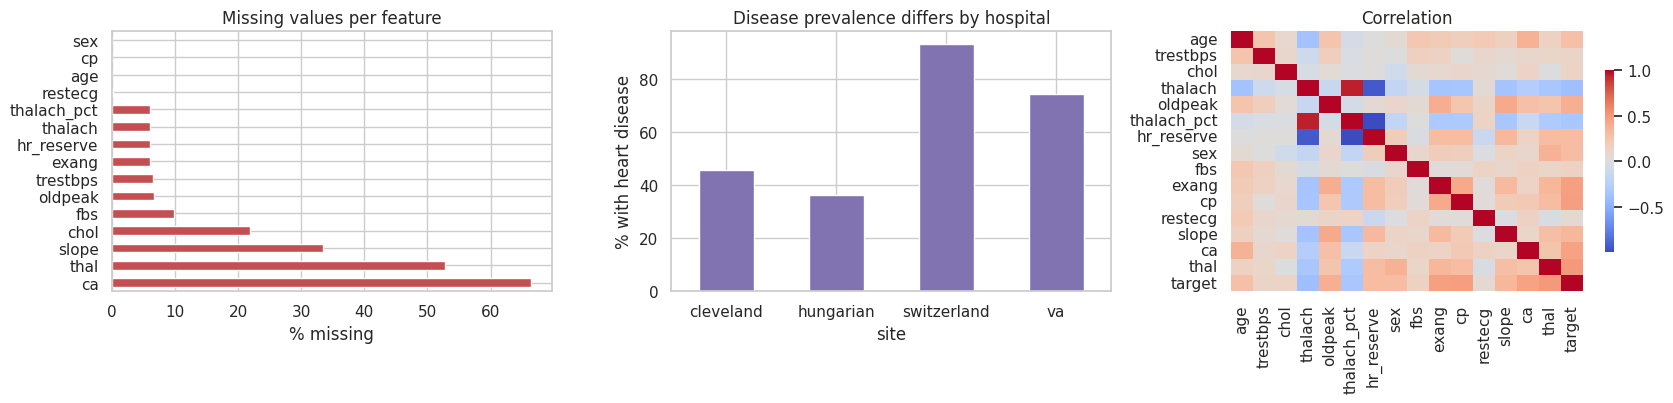

In [ ]:
df = all_df.copy()
for c in ["chol", "trestbps"]: df.loc[df[c] == 0, c] = np.nan            # impossible zeros = missing
raw_cols = [c for c in cols if c != "target"]
df = df.drop_duplicates(subset=raw_cols + ["target", "site"]).reset_index(drop=True)
df["hr_max_pred"] = 220 - df["age"]
df["thalach_pct"] = df["thalach"] / df["hr_max_pred"]       # % of age-predicted max heart rate
df["hr_reserve"] = df["hr_max_pred"] - df["thalach"]
df = df.drop(columns="hr_max_pred")
NUM = ["age", "trestbps", "chol", "thalach", "oldpeak", "thalach_pct", "hr_reserve"]
CAT = ["sex", "fbs", "exang", "cp", "restecg", "slope", "ca", "thal"]
FEATS = NUM + CAT
print("Rows after cleaning:", len(df))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
miss = df[FEATS].isna().mean().sort_values(ascending=False) * 100
miss.plot.barh(ax=ax[0], color="#C44E52"); ax[0].set(xlabel="% missing", title="Missing values per feature")
df.groupby("site")["target"].agg(["mean"]).mul(100).plot.bar(ax=ax[1], legend=False, rot=0, color="#8172B2")
ax[1].set(ylabel="% with heart disease", title="Disease prevalence differs by hospital")
sns.heatmap(df[FEATS + ["target"]].corr(), cmap="coolwarm", center=0, ax=ax[2], cbar_kws={"shrink": .7})
ax[2].set_title("Correlation"); plt.tight_layout(); plt.show()

### Cell 11: PART 3 - leakage-free split (stratified by hospital AND class) + CV scheme

Leakage-free split: 20% test set stratified by hospital and class, plus the 5-fold CV scheme. The test split is used once, at the end.

In [ ]:
X, y, site = df[FEATS], df["target"], df["site"]
strat = site.astype(str) + "_" + y.astype(str)
X_tr, X_te, y_tr, y_te, st_tr, st_te = train_test_split(X, y, strat, test_size=0.20, stratify=strat, random_state=SEED)
site_te = st_te.str.rsplit("_", n=1).str[0].values
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
print("train:", X_tr.shape, "test:", X_te.shape)

train: (734, 15) test: (184, 15)


### Cell 12: PART 3 - preprocessing builders (everything fitted inside CV folds, no leakage)

Preprocessing builders: imputation, scaling and one-hot encoding live inside the pipeline so they are fitted on training folds only. Includes a scikit-learn-compatible CatBoost wrapper.

In [ ]:
def make_prep(poly=False, flags=True):
    num = [("imp", SimpleImputer(strategy="median", add_indicator=flags)), ("sc", StandardScaler())]
    if poly: num += [("poly", PolynomialFeatures(2, include_bias=False)), ("sc2", StandardScaler())]
    cat = [("imp", SimpleImputer(strategy="constant", fill_value=-1)),
           ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]
    return ColumnTransformer([("num", Pipeline(num), NUM), ("cat", Pipeline(cat), CAT)])

def wrap(model, poly=False, flags=True):
    return Pipeline([("prep", make_prep(poly, flags)), ("clf", model)])

class CatBoostSK(ClassifierMixin, BaseEstimator):
    """sklearn-clonable CatBoost; the LAST n_cat columns are categorical."""
    def __init__(self, n_cat=0, iterations=500, depth=4, learning_rate=0.03, l2_leaf_reg=6, random_seed=SEED):
        self.n_cat = n_cat; self.iterations = iterations; self.depth = depth
        self.learning_rate = learning_rate; self.l2_leaf_reg = l2_leaf_reg; self.random_seed = random_seed
    def fit(self, X, y):
        X = pd.DataFrame(X); self.classes_ = np.unique(y)
        self.model_ = CatBoostClassifier(iterations=self.iterations, depth=self.depth, learning_rate=self.learning_rate,
                                         l2_leaf_reg=self.l2_leaf_reg, random_seed=self.random_seed, verbose=0, thread_count=2)
        self.model_.fit(X, np.asarray(y), cat_features=list(range(X.shape[1] - self.n_cat, X.shape[1]))); return self
    def predict_proba(self, X): return self.model_.predict_proba(pd.DataFrame(X))
    def predict(self, X): return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

def catboost_pipe():
    def f(Xd):
        Xd = Xd.copy()
        for c in CAT: Xd[c] = Xd[c].fillna(-1).astype(str)          # NaN becomes its own category
        return Xd[NUM + CAT]
    return Pipeline([("fe", FunctionTransformer(f)), ("clf", CatBoostSK(n_cat=len(CAT)))])

### Cell 13: PART 3 - AutoML (TPOT) on the TRAIN split only; its structure is frozen afterwards

AutoML (TPOT) kept from the paper: searched on the training split only, then frozen.

In [ ]:
Xt = make_prep(poly=True).fit_transform(X_tr)
tpot = TPOTClassifier(search_space="linear", scorers=["roc_auc"], scorers_weights=[1], cv=5,
                      generations=2 if FAST else 8, population_size=6 if FAST else 25,
                      random_state=SEED, n_jobs=2, verbose=0)
tpot.fit(Xt, y_tr.values)
tpot_pipe = tpot.fitted_pipeline_
print("TPOT selected pipeline:\n", tpot_pipe)

INFO:distributed.scheduler:State start
INFO:distributed.scheduler:  Scheduler at:     tcp://127.0.0.1:41951
INFO:distributed.scheduler:  dashboard at:  http://127.0.0.1:8787/status
INFO:distributed.scheduler:Registering Worker plugin shuffle
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:46265'
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:39543'
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:39907 name: 0
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:39907
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:51732
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:35793 name: 1
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:35793
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:51740
INFO:distributed.scheduler:Receive client connection: Client-14bc4c4c-c64e-11f1-81dc-0242ac1c000c
INFO:distributed.core:Starting establish

TPOT selected pipeline:
 Pipeline(steps=[('maxabsscaler', MaxAbsScaler()),
                ('selectfwe', SelectFwe(alpha=0.0023648971022)),
                ('featureunion-1',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()),
                                                ('passthrough',
                                                 Passthrough())])),
                ('featureunion-2',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()),
                                                ('passthrough',
                                                 Passthrough())])),
                ('lineardiscriminantanalysis',
                 LinearDiscriminantAnalysis(shrinkage=0.3556309938772,
                                            solver=np.str_('lsqr')))])


### Cell 14: PART 3 - hyper-parameter search (train split only, 5-fold CV, scoring = ROC-AUC)

Randomised hyperparameter search (training split only, 5-fold CV, ROC-AUC) for LogReg, SVM, ExtraTrees, LightGBM, XGBoost and CatBoost.

In [ ]:
N_IT = 4 if FAST else 30
searches = {
    "LogReg": (wrap(LogisticRegression(max_iter=5000)),
               {"clf__C": loguniform(1e-3, 1e2), "clf__class_weight": [None, "balanced"]}, N_IT),
    "SVM-RBF": (wrap(SVC(probability=True, random_state=SEED)),
                {"clf__C": loguniform(1e-1, 1e2), "clf__gamma": loguniform(1e-4, 1e-1),
                 "clf__class_weight": [None, "balanced"]}, N_IT),
    "ExtraTrees": (wrap(ExtraTreesClassifier(random_state=SEED, n_jobs=2)),
                   {"clf__n_estimators": randint(200, 600), "clf__max_depth": [3, 4, 5, 6, None],
                    "clf__min_samples_leaf": randint(1, 8), "clf__max_features": ["sqrt", 0.5, 0.8]}, N_IT),
    "LightGBM": (wrap(LGBMClassifier(subsample_freq=1, random_state=SEED, n_jobs=2, verbose=-1)),
                 {"clf__num_leaves": randint(4, 16), "clf__max_depth": randint(2, 5),
                  "clf__learning_rate": loguniform(0.01, 0.2), "clf__n_estimators": randint(100, 500),
                  "clf__subsample": uniform(0.6, 0.4), "clf__colsample_bytree": uniform(0.5, 0.5),
                  "clf__min_child_samples": randint(5, 25), "clf__reg_lambda": loguniform(0.5, 10)}, N_IT),
    "XGBoost": (wrap(XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=2)),
                {"clf__max_depth": randint(2, 5), "clf__learning_rate": loguniform(0.01, 0.2),
                 "clf__n_estimators": randint(100, 500), "clf__subsample": uniform(0.6, 0.4),
                 "clf__colsample_bytree": uniform(0.5, 0.5), "clf__min_child_weight": randint(1, 8),
                 "clf__reg_lambda": loguniform(0.5, 10)}, N_IT),
    "CatBoost": (catboost_pipe(),
                 {"clf__depth": [3, 4, 5, 6], "clf__learning_rate": loguniform(0.02, 0.1),
                  "clf__l2_leaf_reg": [3, 6, 10], "clf__iterations": [150] if FAST else [300, 500]}, 3 if FAST else 8),
}
tuned, search_log = {}, []
for name, (pipe, space, n_iter) in searches.items():
    s = RandomizedSearchCV(pipe, space, n_iter=n_iter, scoring="roc_auc", cv=cv5, random_state=SEED, n_jobs=-1, refit=False)
    s.fit(X_tr, y_tr)
    tuned[name] = clone(pipe).set_params(**s.best_params_)
    search_log.append({"model": name, "best CV AUC": round(s.best_score_, 4),
                       "best params": {k.replace("clf__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in s.best_params_.items()}})
pd.set_option("display.max_colwidth", 200); print(pd.DataFrame(search_log).to_string(index=False))

     model  best CV AUC                                                                                                                                                                     best params
    LogReg       0.9053                                                                                                                                             {'C': 0.1695, 'class_weight': None}
   SVM-RBF       0.9042                                                                                                                     {'C': 65.4121, 'class_weight': 'balanced', 'gamma': 0.0004}
ExtraTrees       0.9008                                                                                            {'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 513}
  LightGBM       0.8994 {'colsample_bytree': 0.537, 'learning_rate': 0.0293, 'max_depth': 2, 'min_child_samples': 11, 'n_estimators': 300, 'num_leaves': 11, 'reg_lambda': 1.9218, 'subsample': 0.6382}


### Cell 15: PART 3 - assemble all candidate models (tuned singles, TPOT, soft-vote, stacking, calibrated stacking)

Assembles all ten candidate models: tuned singles, TPOT, soft vote, stacking (out-of-fold, LogReg meta-learner) and calibrated stacking.

In [ ]:
tpot_model = wrap(clone(tpot_pipe), poly=True)
singles = dict(tuned); singles["TPOT (AutoML)"] = tpot_model
est_list = [(k, v) for k, v in singles.items()]
soft_vote = VotingClassifier([(k.replace(" ", "_"), clone(v)) for k, v in est_list], voting="soft")
stack = StackingClassifier([(k.replace(" ", "_"), clone(v)) for k, v in est_list],
                           final_estimator=LogisticRegression(C=0.5, max_iter=2000),
                           stack_method="predict_proba", cv=cv5)
stack_cal = CalibratedClassifierCV(clone(stack), method="sigmoid", cv=StratifiedKFold(3, shuffle=True, random_state=SEED))
models = dict(singles); models["Soft vote (all)"] = soft_vote; models["Stack (LogReg meta)"] = stack
models["Stack (calibrated)"] = stack_cal
print(list(models))

['LogReg', 'SVM-RBF', 'ExtraTrees', 'LightGBM', 'XGBoost', 'CatBoost', 'TPOT (AutoML)', 'Soft vote (all)', 'Stack (LogReg meta)', 'Stack (calibrated)']


### Cell 16: PART 3 - honest 5-fold CV on the TRAIN split (model comparison)

5-fold CV on the training split for every model. The final model is selected from this table, so the test split never influences selection.

                     CV_acc  CV_acc_sd  CV_auc  CV_auc_sd
model                                                    
TPOT (AutoML)         0.824      0.040   0.903      0.045
Soft vote (all)       0.826      0.044   0.899      0.047
Stack (LogReg meta)   0.822      0.042   0.899      0.047
CatBoost              0.820      0.050   0.898      0.048
LogReg                0.820      0.037   0.898      0.044
SVM-RBF               0.820      0.047   0.896      0.048
LightGBM              0.820      0.046   0.892      0.047
ExtraTrees            0.820      0.056   0.892      0.050
XGBoost               0.815      0.043   0.891      0.046


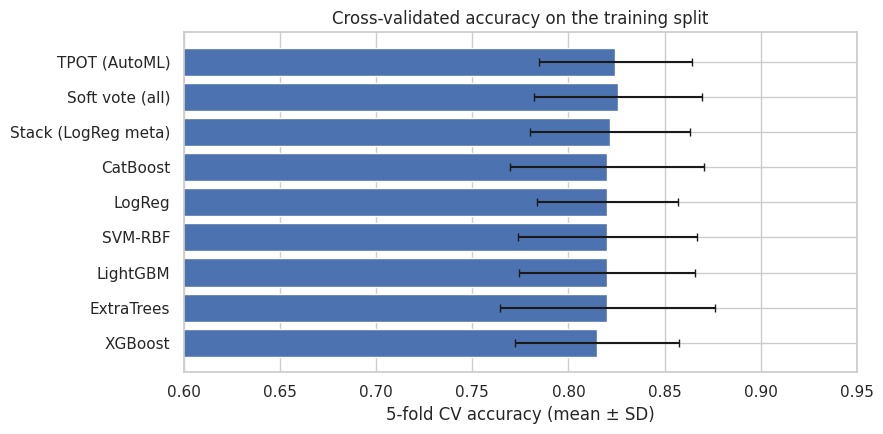

In [ ]:
cv_rows = []
for name, m in models.items():
    if name == "Stack (calibrated)": continue            # same structure as the plain stack
    cv = cross_validate(m, X_tr, y_tr, cv=StratifiedKFold(5, shuffle=True, random_state=SEED + 1),
                        scoring=["accuracy", "roc_auc"], n_jobs=1)
    cv_rows.append(dict(model=name, CV_acc=cv["test_accuracy"].mean(), CV_acc_sd=cv["test_accuracy"].std(),
                        CV_auc=cv["test_roc_auc"].mean(), CV_auc_sd=cv["test_roc_auc"].std()))
cvtab = pd.DataFrame(cv_rows).set_index("model").sort_values("CV_auc", ascending=False)
print(cvtab.round(3).to_string())
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(cvtab.index[::-1], cvtab["CV_acc"][::-1], xerr=cvtab["CV_acc_sd"][::-1], color="#4C72B0", capsize=3)
ax.set(xlim=(0.6, 0.95), xlabel="5-fold CV accuracy (mean ± SD)", title="Cross-validated accuracy on the training split")
plt.tight_layout(); plt.show()

### Cell 17: PART 3 - fit every model on the TRAIN split and predict the untouched TEST split (once)

Fits every model on the training split and stores its test-set probabilities. The test split is touched here and nowhere else.

In [ ]:
fitted, probs = {}, {}
for name, m in models.items():
    fitted[name] = clone(m).fit(X_tr, y_tr)
    probs[name] = fitted[name].predict_proba(X_te)[:, 1]
print("fitted:", len(fitted), "models")

fitted: 10 models


### Cell 18: PART 3 - per-model visualisation (confusion matrix, ROC, PR, calibration) for EVERY model

Four-panel visualisation for every model.

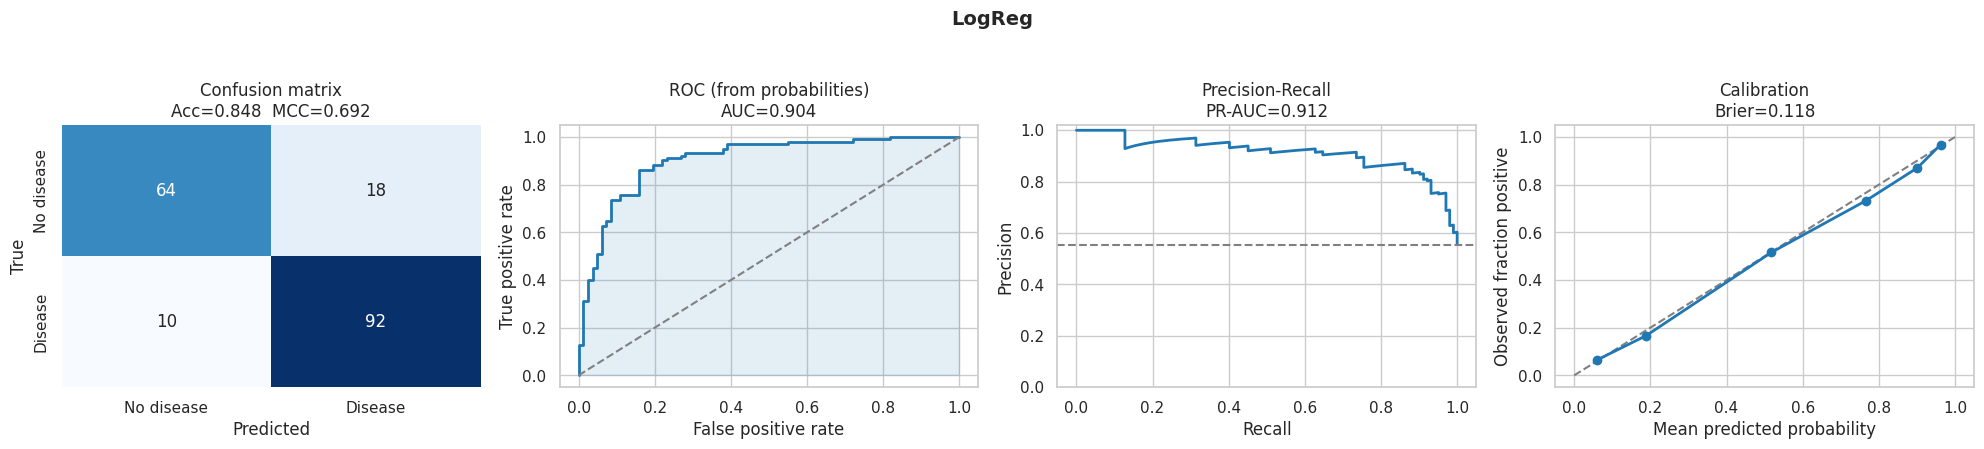

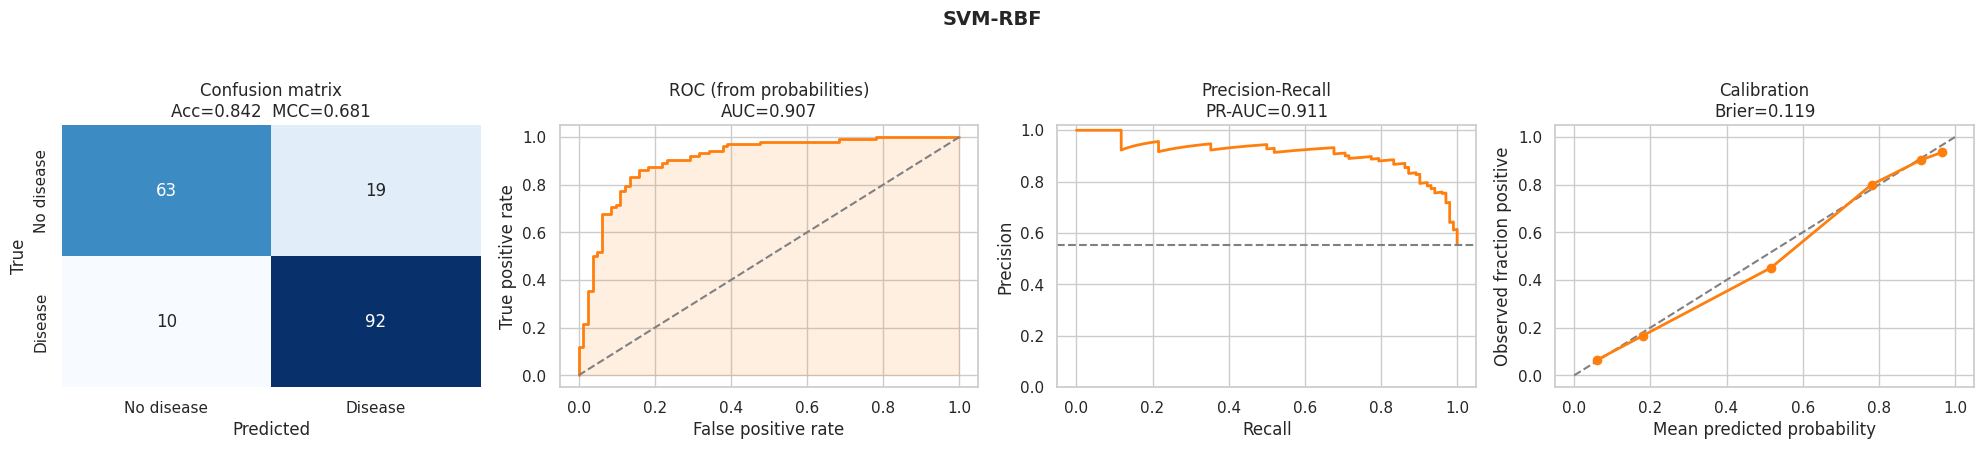

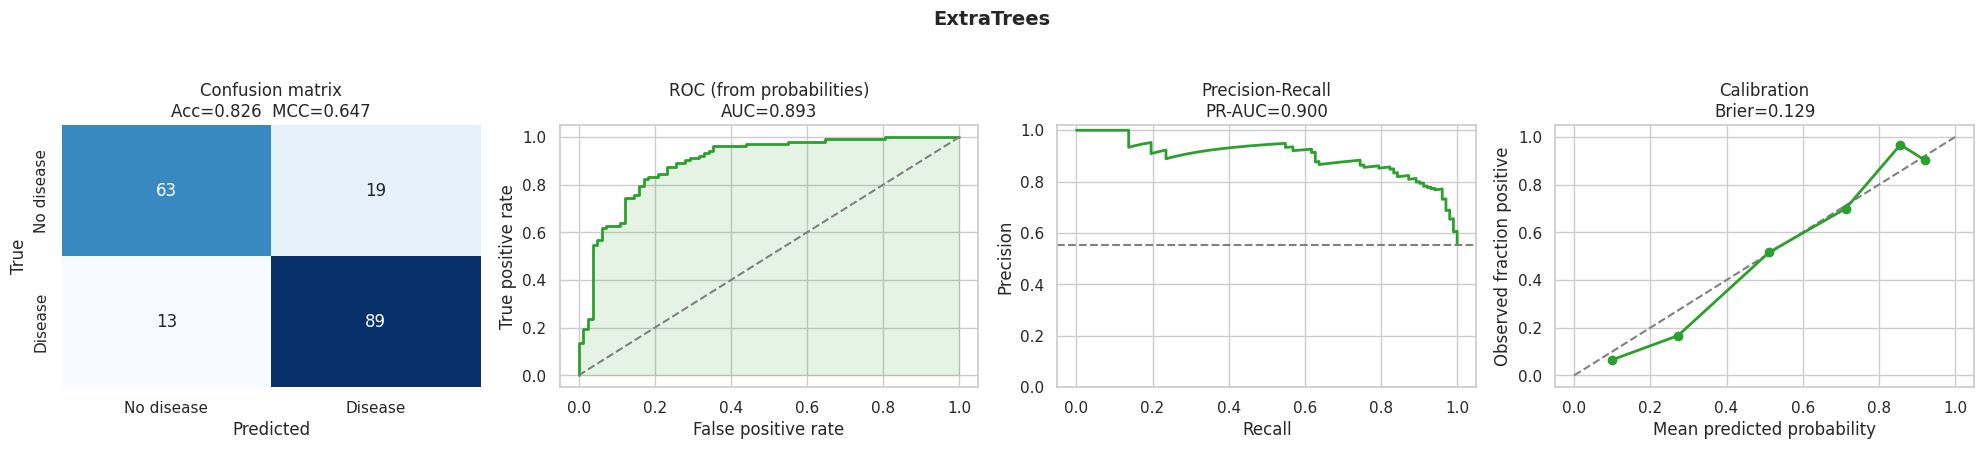

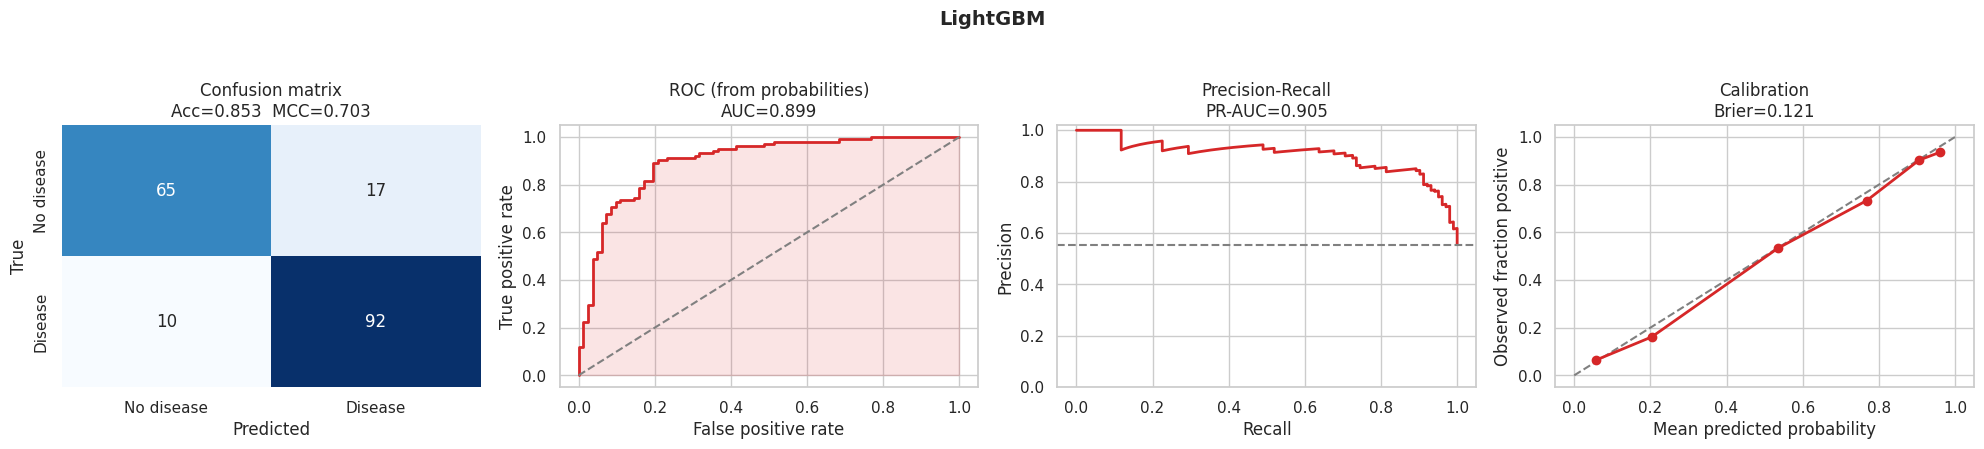

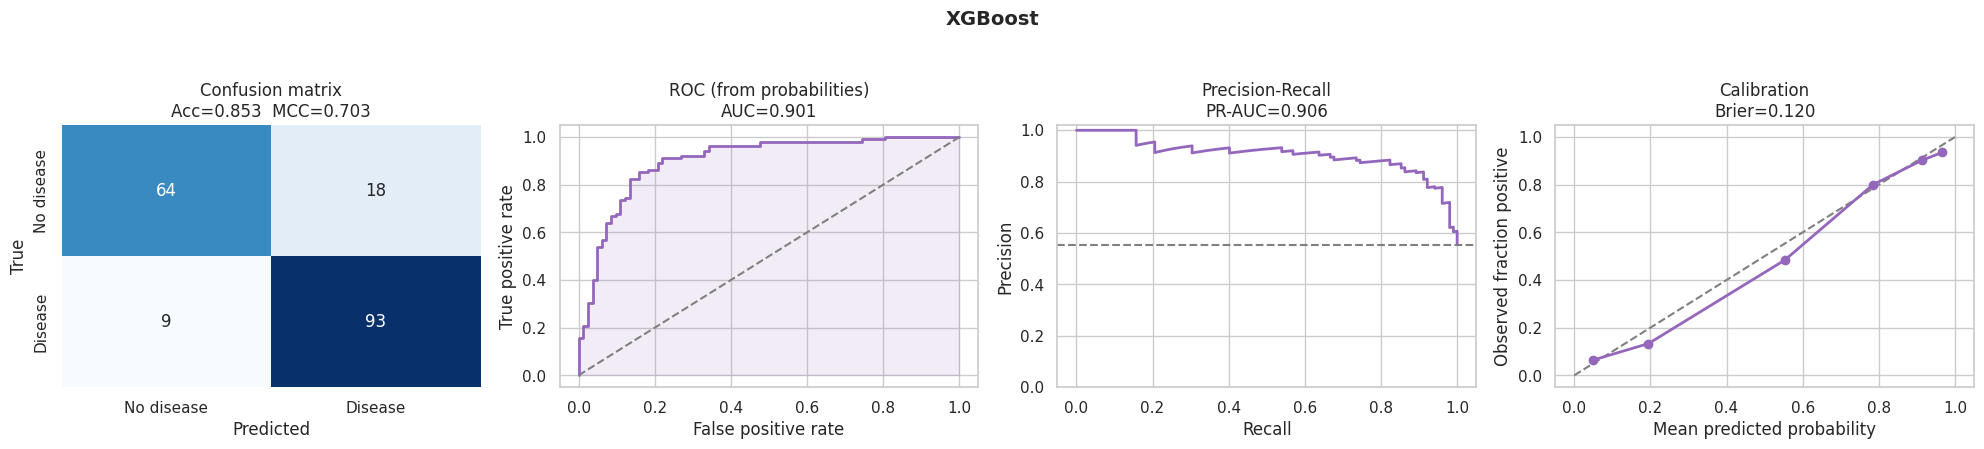

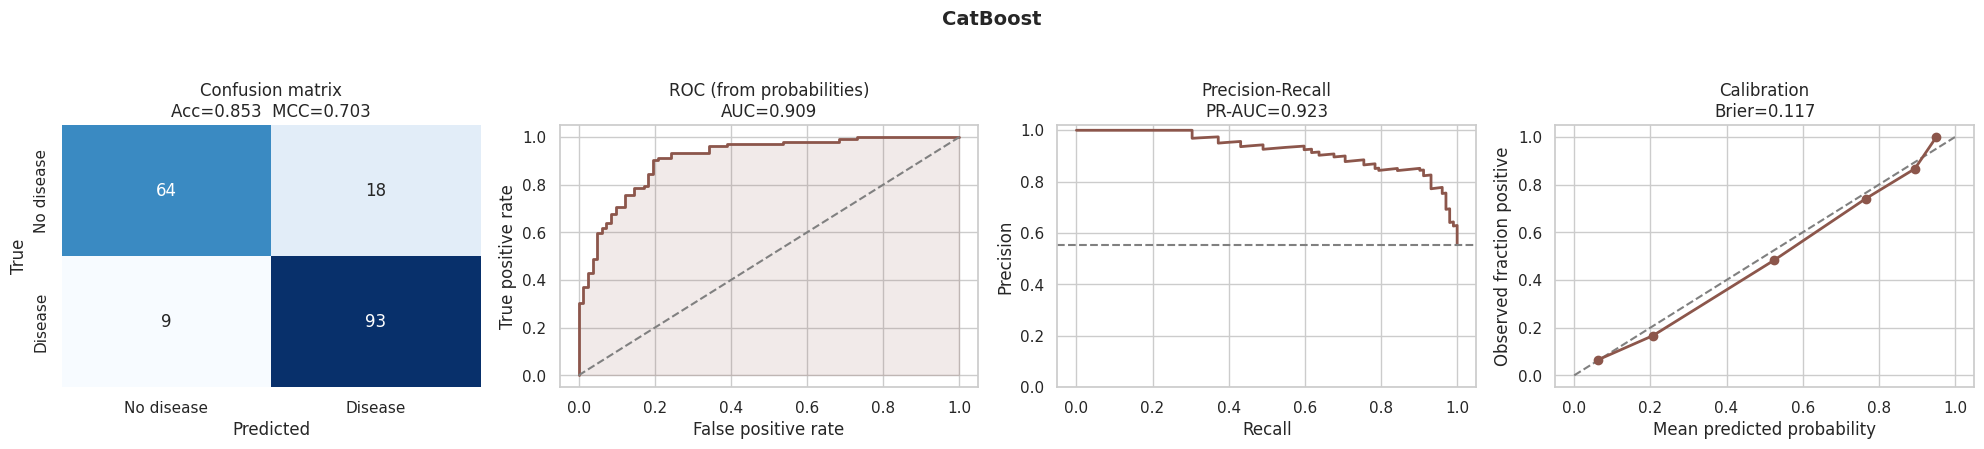

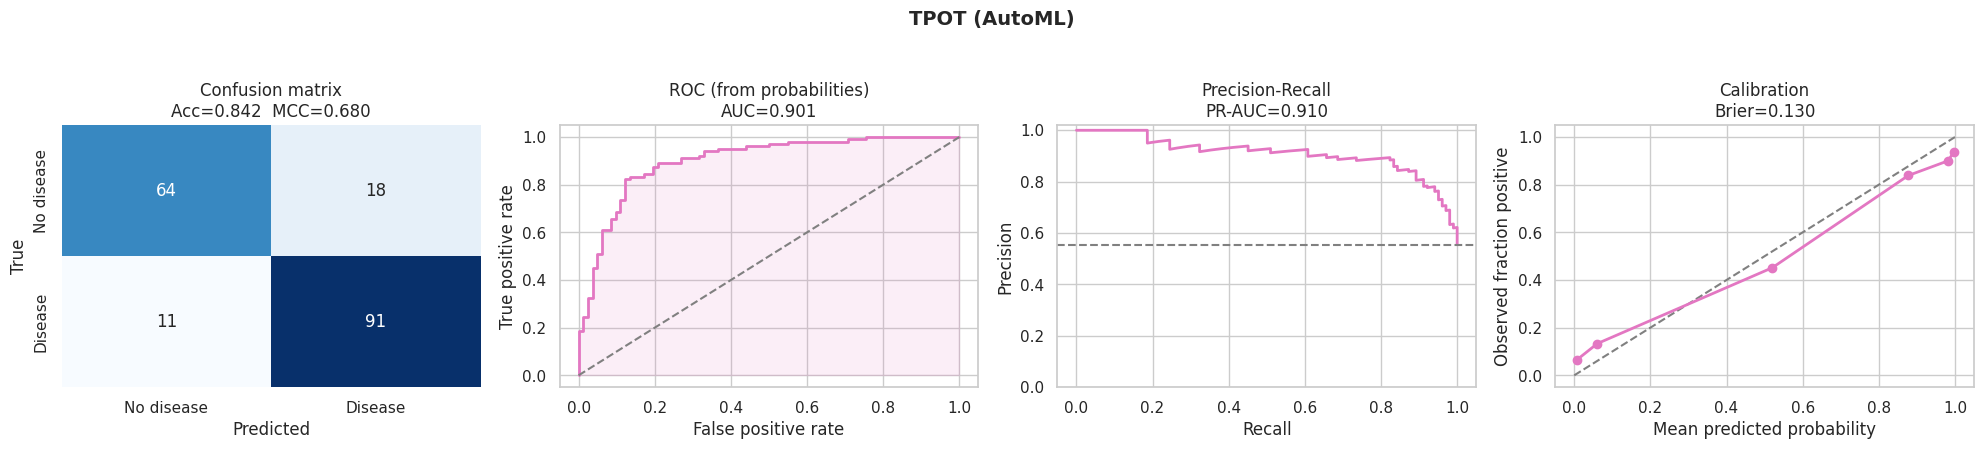

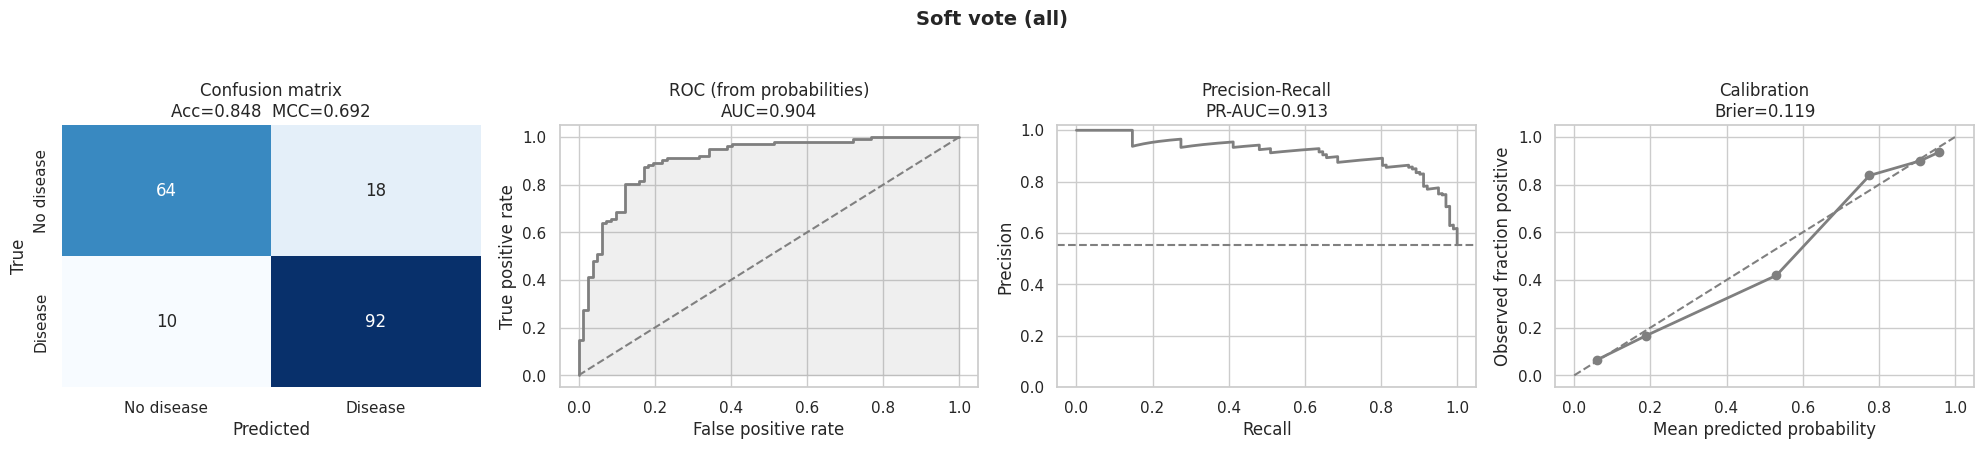

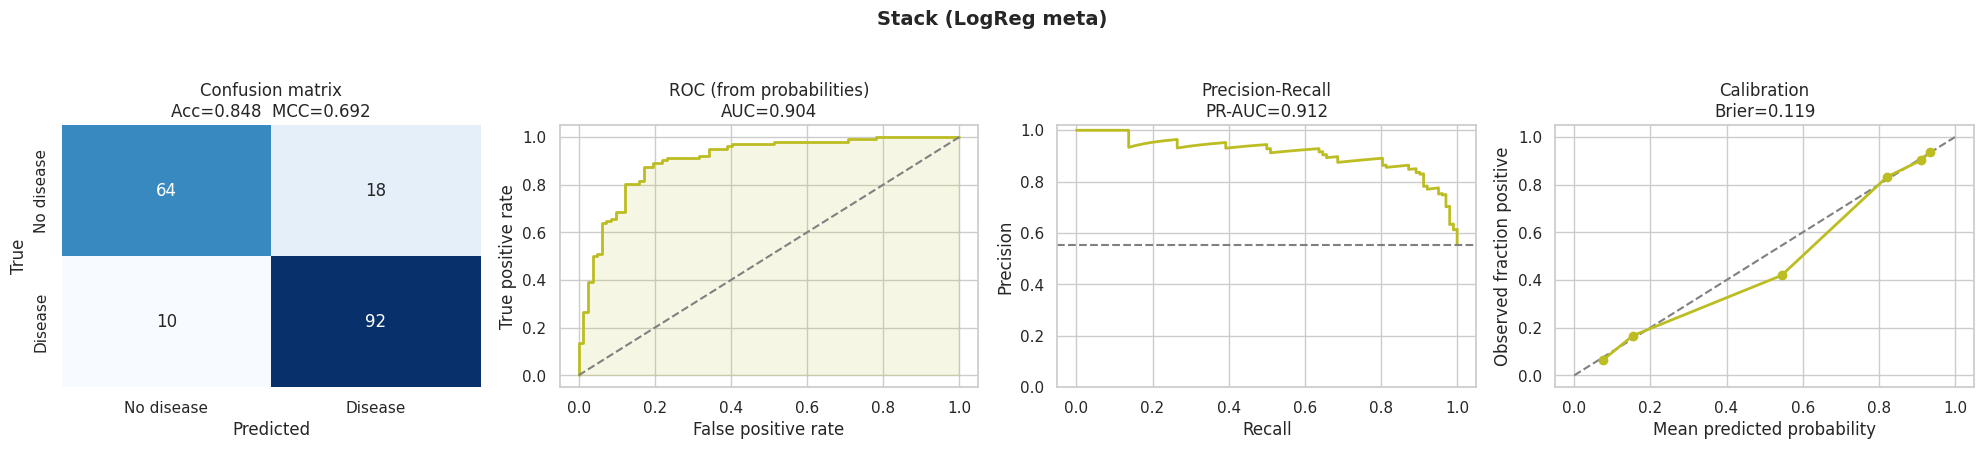

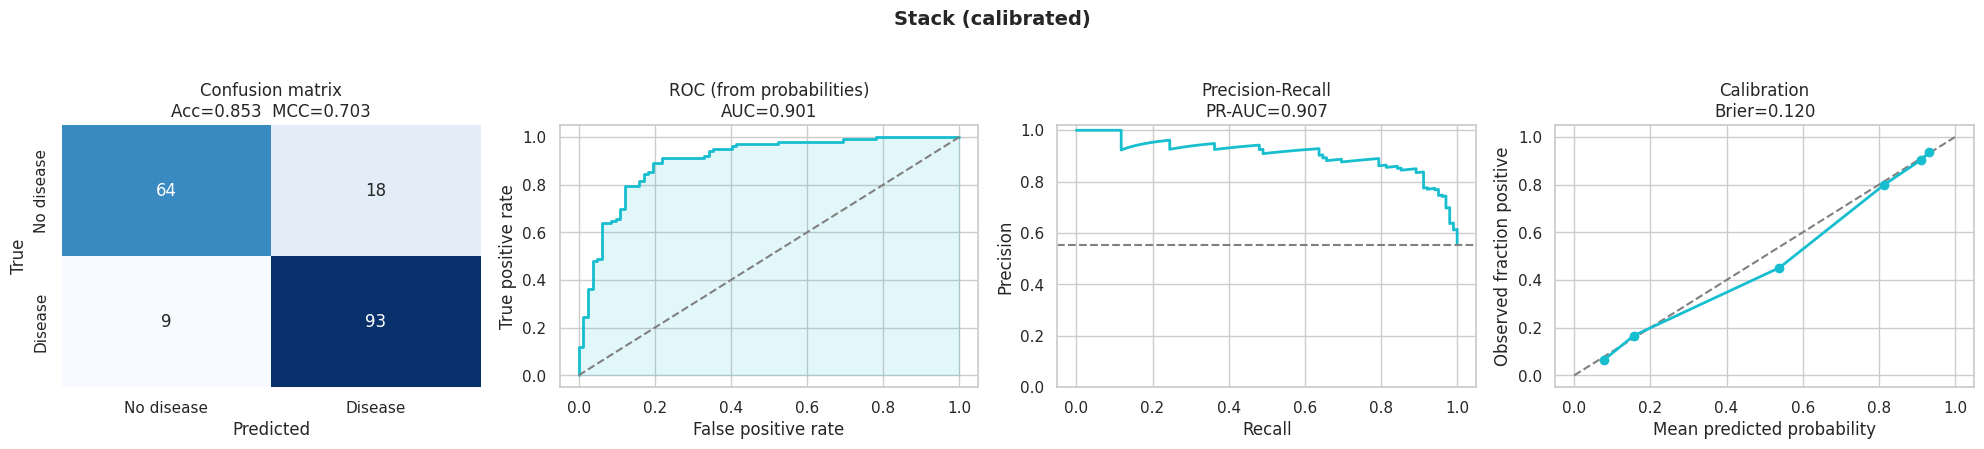

In [ ]:
results = {}
for i, (name, p) in enumerate(probs.items()):
    results[name] = model_panel(name, y_te, p, color=sns.color_palette("tab10")[i % 10])

### Cell 19: PART 3 - results table with bootstrap 95% confidence intervals

Results table with all metrics and 95% bootstrap confidence intervals.

In [ ]:
tab = pd.DataFrame(results).T[["Accuracy", "BalAcc", "Recall", "Precision", "F1", "MCC", "ROC_AUC", "Brier"]].astype(float)
ci = {n: bootstrap_ci(y_te, p, 300 if FAST else 1000) for n, p in probs.items()}
tab["Acc 95% CI"] = [f"[{ci[n]['Accuracy'][0]:.3f}, {ci[n]['Accuracy'][1]:.3f}]" for n in tab.index]
tab["AUC 95% CI"] = [f"[{ci[n]['ROC_AUC'][0]:.3f}, {ci[n]['ROC_AUC'][1]:.3f}]" for n in tab.index]
tab = tab.sort_values("ROC_AUC", ascending=False)
print(tab.round(3).to_string())

                     Accuracy  BalAcc  Recall  Precision     F1    MCC  ROC_AUC  Brier      Acc 95% CI      AUC 95% CI
CatBoost                0.853   0.846   0.912      0.838  0.873  0.703    0.909  0.117  [0.799, 0.897]  [0.864, 0.947]
SVM-RBF                 0.842   0.835   0.902      0.829  0.864  0.681    0.907  0.119  [0.788, 0.891]  [0.859, 0.947]
Soft vote (all)         0.848   0.841   0.902      0.836  0.868  0.692    0.904  0.119  [0.799, 0.897]  [0.855, 0.945]
LogReg                  0.848   0.841   0.902      0.836  0.868  0.692    0.904  0.118  [0.799, 0.897]  [0.857, 0.945]
Stack (LogReg meta)     0.848   0.841   0.902      0.836  0.868  0.692    0.904  0.119  [0.799, 0.897]  [0.856, 0.945]
XGBoost                 0.853   0.846   0.912      0.838  0.873  0.703    0.901  0.120  [0.799, 0.897]  [0.852, 0.942]
Stack (calibrated)      0.853   0.846   0.912      0.838  0.873  0.703    0.901  0.120  [0.799, 0.897]  [0.851, 0.943]
TPOT (AutoML)           0.842   0.836   0.892   

### Cell 20: FINAL 1 - the headline: paper (duplicates) vs same code (no duplicates) vs corrected pipeline

**Final visual 1:** paper accuracy with duplicates vs the same code without duplicates vs the corrected pipeline.

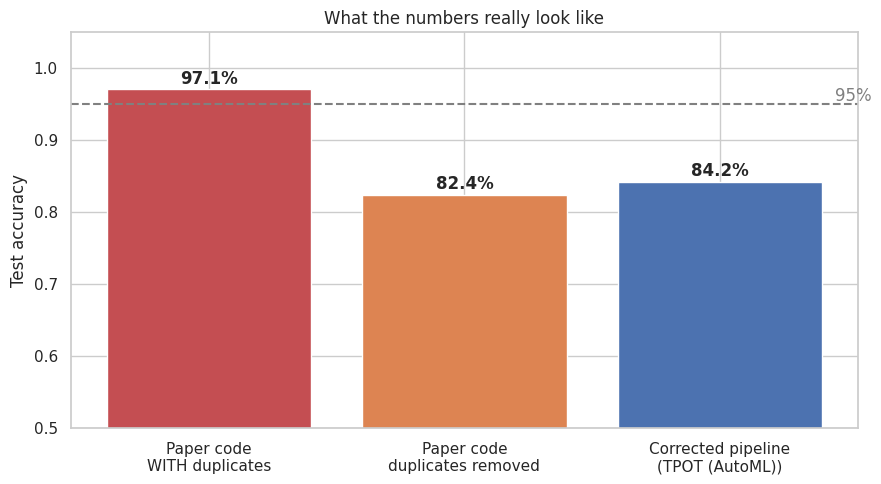

Note: the three bars use different datasets (1025 rows incl. duplicates / 302 unique Cleveland / 918 four-site rows).


In [ ]:
best_cv = cvtab.index[0]                                        # selection rule: highest CV AUC on the TRAIN split
best_acc_test = results[best_cv]["Accuracy"]
labels = ["Paper code\nWITH duplicates", "Paper code\nduplicates removed", f"Corrected pipeline\n({best_cv})"]
vals = [res_paper_dup["metrics"]["Test_Accuracy"], res_paper_nodup["metrics"]["Test_Accuracy"], best_acc_test]
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(labels, vals, color=["#C44E52", "#DD8452", "#4C72B0"])
for b_, v in zip(bars, vals): ax.text(b_.get_x() + b_.get_width() / 2, v + .008, f"{v:.1%}", ha="center", fontweight="bold")
ax.axhline(0.95, ls="--", c="gray"); ax.text(2.45, .955, "95%", color="gray")
ax.set(ylim=(0.5, 1.05), ylabel="Test accuracy", title="What the numbers really look like"); plt.tight_layout(); plt.show()
print("Note: the three bars use different datasets (1025 rows incl. duplicates / 302 unique Cleveland / 918 four-site rows).")

### Cell 21: FINAL 2 - all models compared (metrics, ROC overlay, calibration overlay)

**Final visual 2:** all models compared (metric bars, overlaid ROC curves, overlaid calibration curves).

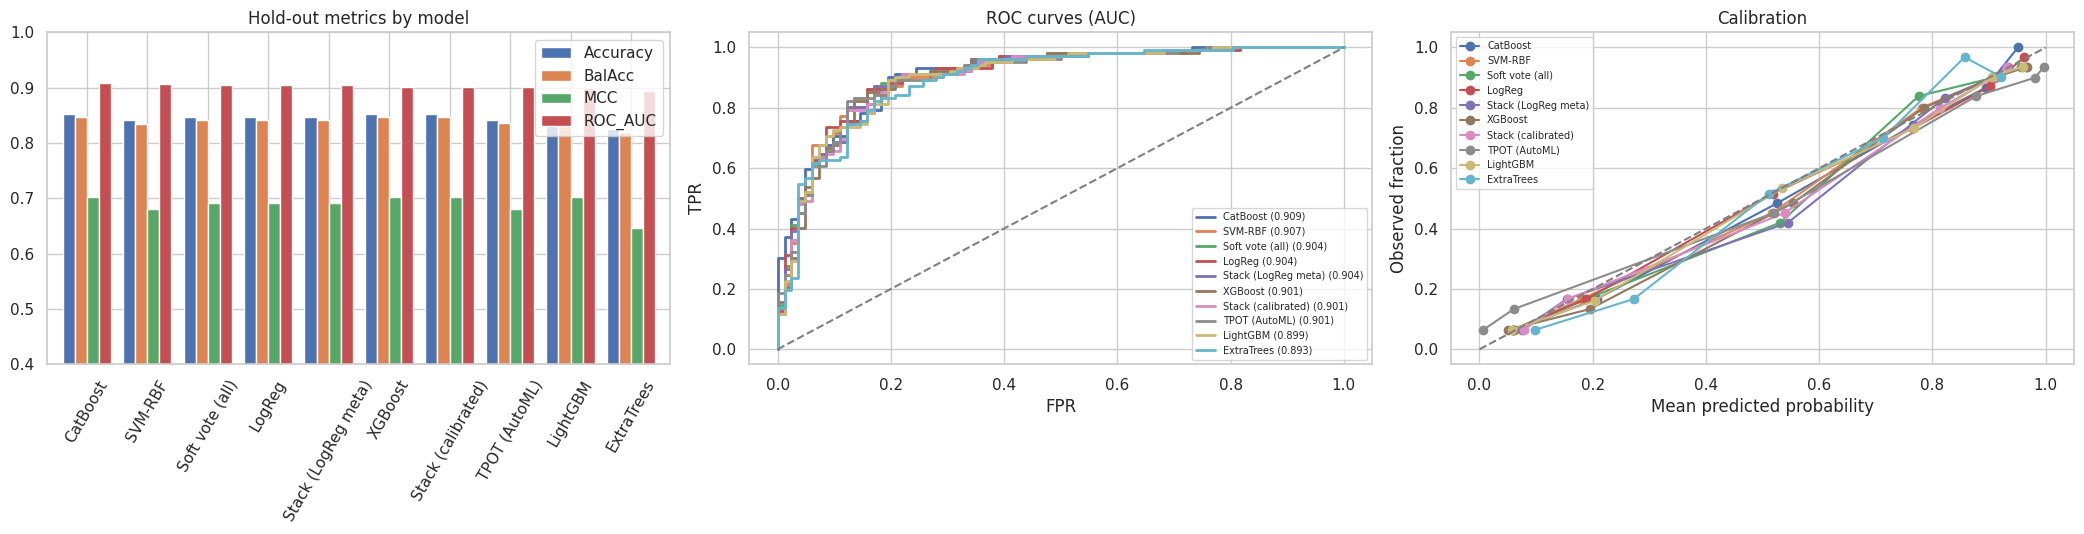

In [ ]:
order = tab.index.tolist()
fig, ax = plt.subplots(1, 3, figsize=(21, 5.5))
tab[["Accuracy", "BalAcc", "MCC", "ROC_AUC"]].loc[order].plot.bar(ax=ax[0], width=0.8)
ax[0].set(ylim=(0.4, 1.0), title="Hold-out metrics by model"); ax[0].tick_params(axis="x", rotation=60)
for i, n in enumerate(order):
    f, t, _ = roc_curve(y_te, probs[n]); ax[1].plot(f, t, lw=2, label=f"{n} ({tab.loc[n, 'ROC_AUC']:.3f})")
ax[1].plot([0, 1], [0, 1], "--", c="gray"); ax[1].set(xlabel="FPR", ylabel="TPR", title="ROC curves (AUC)"); ax[1].legend(fontsize=7)
for n in order:
    fy, fx = calibration_curve(y_te, probs[n], n_bins=6, strategy="quantile"); ax[2].plot(fx, fy, "o-", label=n)
ax[2].plot([0, 1], [0, 1], "--", c="gray"); ax[2].set(xlabel="Mean predicted probability", ylabel="Observed fraction", title="Calibration"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

### Cell 22: FINAL 3 - accuracy with 95% CI and the 95% target line

**Final visual 3:** accuracy with 95% intervals against the 95% target line.

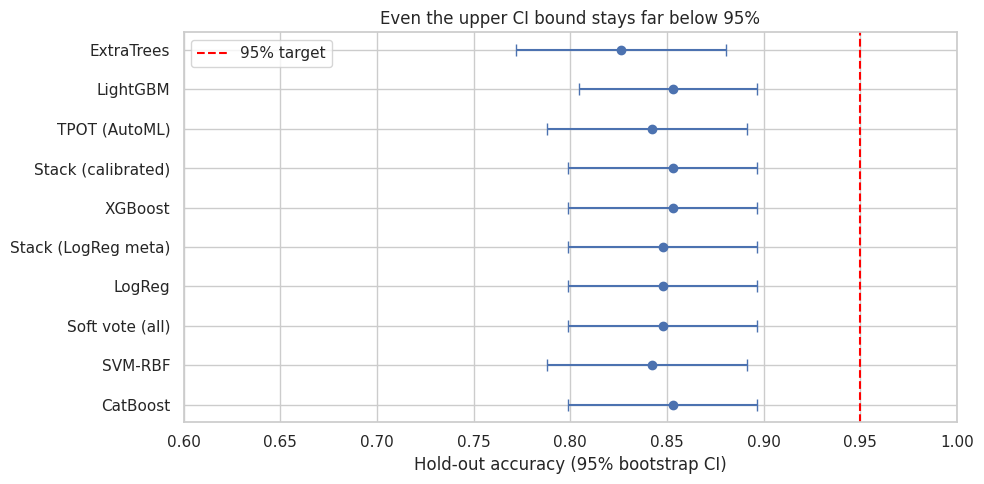

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
accs = tab["Accuracy"].values; lo = np.array([ci[n]["Accuracy"][0] for n in tab.index]); hi = np.array([ci[n]["Accuracy"][1] for n in tab.index])
ax.errorbar(accs, range(len(accs)), xerr=[accs - lo, hi - accs], fmt="o", color="#4C72B0", capsize=4)
ax.axvline(0.95, ls="--", c="red", label="95% target"); ax.set_yticks(range(len(accs))); ax.set_yticklabels(tab.index)
ax.set(xlim=(0.6, 1.0), xlabel="Hold-out accuracy (95% bootstrap CI)", title="Even the upper CI bound stays far below 95%"); ax.legend()
plt.tight_layout(); plt.show()

### Cell 23: FINAL 4 - the selected model, hospital by hospital

**Final visual 4:** the selected model per hospital, with the majority-class baseline.

              n  Accuracy  BalAcc  ROC_AUC  majority_baseline
site                                                         
cleveland    61     0.869   0.871    0.963              0.541
hungarian    58     0.828   0.813    0.858              0.638
switzerland  25     0.920   0.728    0.848              0.920
va           40     0.775   0.617    0.683              0.750


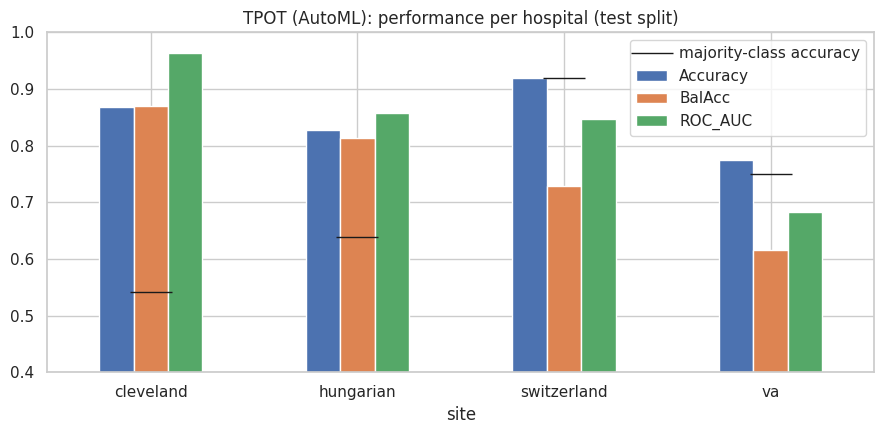

In [ ]:
p_best = probs[best_cv]; rows = []
for s_ in sorted(set(site_te)):
    m_ = site_te == s_; r = report(y_te.values[m_], p_best[m_])
    rows.append(dict(site=s_, n=r["n"], Accuracy=r["Accuracy"], BalAcc=r["BalAcc"], ROC_AUC=r["ROC_AUC"],
                     majority_baseline=max(y_te.values[m_].mean(), 1 - y_te.values[m_].mean())))
site_tab = pd.DataFrame(rows).set_index("site"); print(site_tab.round(3).to_string())
fig, ax = plt.subplots(figsize=(9, 4.5)); site_tab[["Accuracy", "BalAcc", "ROC_AUC"]].plot.bar(ax=ax, rot=0)
ax.plot(range(len(site_tab)), site_tab["majority_baseline"], "k_", markersize=30, label="majority-class accuracy")
ax.set(ylim=(0.4, 1.0), title=f"{best_cv}: performance per hospital (test split)"); ax.legend(); plt.tight_layout(); plt.show()

### Cell 24: FINAL 5 - explainability of the SELECTED model: SHAP (global) + LIME (one patient)

**Final visual 5:** SHAP (global importance and direction of effect) and LIME (one patient) for the selected model. Can take several minutes.

PermutationExplainer explainer: 41it [00:15,  1.51it/s]


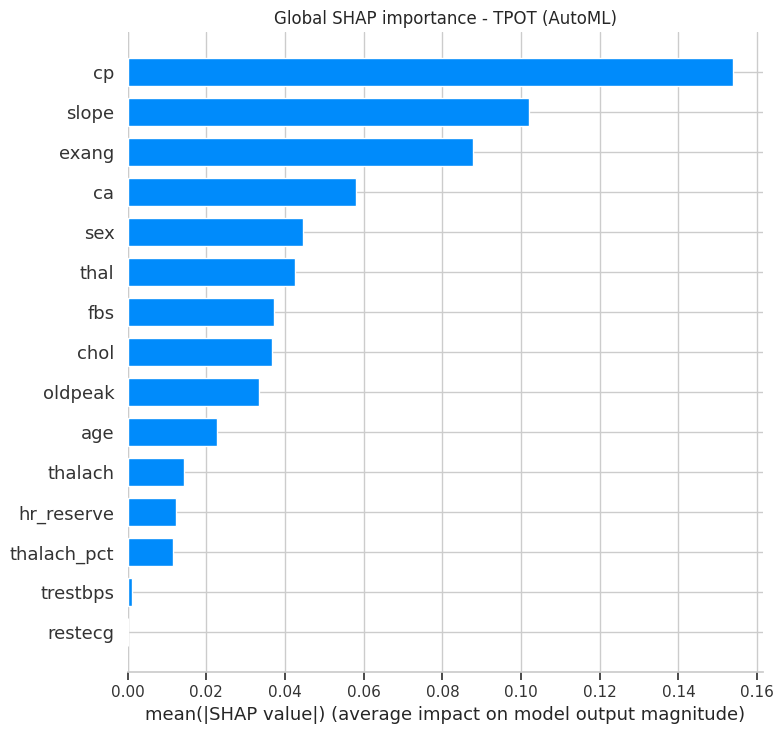

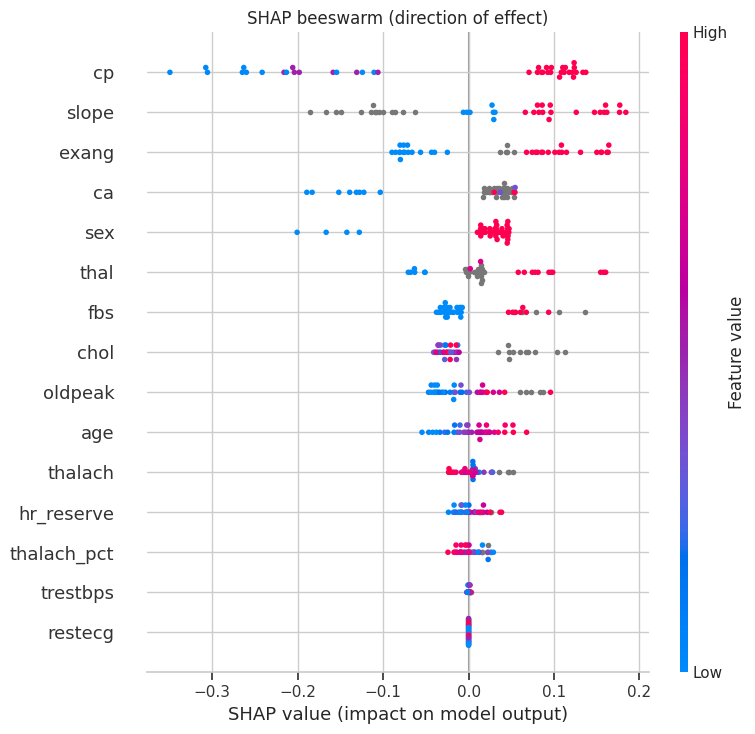

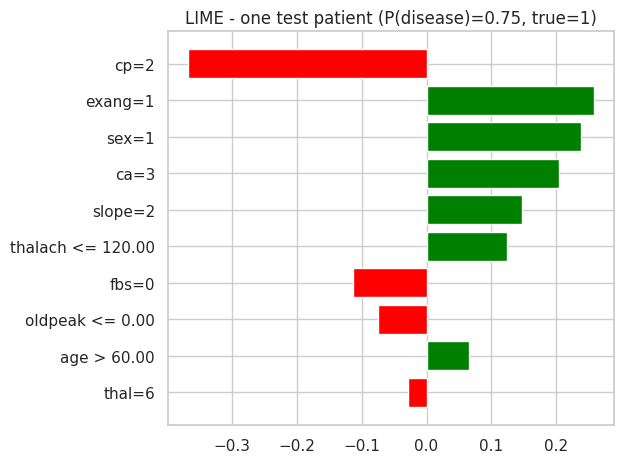

In [ ]:
import shap
from lime.lime_tabular import LimeTabularExplainer
final_model = fitted[best_cv]
f_pred = lambda d: final_model.predict_proba(pd.DataFrame(d, columns=FEATS).astype(X_tr.dtypes.to_dict()))[:, 1]
N_SHAP = 8 if FAST else 40
Xs = X_te.iloc[:N_SHAP]
sv = shap.Explainer(f_pred, shap.maskers.Independent(X_tr, max_samples=40), algorithm="permutation", seed=SEED)(Xs)
plt.figure(); shap.summary_plot(sv.values, Xs, plot_type="bar", show=False); plt.title(f"Global SHAP importance - {best_cv}"); plt.tight_layout(); plt.show()
plt.figure(); shap.summary_plot(sv.values, Xs, show=False); plt.title("SHAP beeswarm (direction of effect)"); plt.tight_layout(); plt.show()
lime_exp = LimeTabularExplainer(X_tr.fillna(X_tr.median()).values.astype(float), feature_names=FEATS,
                                categorical_features=[FEATS.index(c) for c in CAT], class_names=["No disease", "Disease"],
                                mode="classification", discretize_continuous=True, random_state=SEED)
lime_fn = lambda a: np.c_[1 - f_pred(a), f_pred(a)]
row = X_te.iloc[0].fillna(X_tr.median()).values.astype(float)
e = lime_exp.explain_instance(row, lime_fn, num_features=10, num_samples=1000 if FAST else 3000)
e.as_pyplot_figure(); plt.title(f"LIME - one test patient (P(disease)={p_best[0]:.2f}, true={y_te.iloc[0]})"); plt.tight_layout(); plt.show()

### Cell 25: FINAL 6 - summary table to copy into the paper

Final summary table for the selected model, to copy into the paper.

In [ ]:
final = tab.loc[[best_cv], ["Accuracy", "BalAcc", "Recall", "Precision", "F1", "MCC", "ROC_AUC", "Brier", "Acc 95% CI", "AUC 95% CI"]]
print("Selected model (highest CV AUC on train split):", best_cv); print(final.round(3).to_string())
print("\nPaper claimed 96.75% accuracy. The honest, leakage-free estimate on four-site data is shown above.")

Selected model (highest CV AUC on train split): TPOT (AutoML)
               Accuracy  BalAcc  Recall  Precision     F1   MCC  ROC_AUC  Brier      Acc 95% CI      AUC 95% CI
TPOT (AutoML)     0.842   0.836   0.892      0.835  0.863  0.68    0.901   0.13  [0.788, 0.891]  [0.852, 0.942]

Paper claimed 96.75% accuracy. The honest, leakage-free estimate on four-site data is shown above.


In [ ]:
tmp = X_te.copy(); tmp["y"] = y_te.values; tmp["p"] = probs[best_cv]
tmp["pred"] = (tmp["p"] >= 0.5).astype(int); tmp["slope_missing"] = tmp["slope"].isna()
print(tmp.groupby("slope_missing").apply(lambda d: pd.Series({
    "n": len(d), "acc": (d.pred == d.y).mean(),
    "auc": roc_auc_score(d.y, d.p) if d.y.nunique() > 1 else np.nan})))

                   n       acc       auc
slope_missing                           
False          125.0  0.856000  0.902891
True            59.0  0.813559  0.871429
